# 2. O que os dados mostram?

Vamos responder, com números e gráficos simples, quem cancela, quando e quais características aparecem junto dos cancelamentos. A análise usa as **119.208 reservas da base inteira**, tanto as do treino quanto as do teste; ela descreve o histórico e não mede causalidade.

In [1]:
import sys
from pathlib import Path

RAIZ = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "requirements.txt").exists())
sys.path.insert(0, str(RAIZ / "src"))

from etl import SEED, carregar_dados_tratados
from visual import CORES, aplicar_estilo, salvar_figura, salvar_tabela

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

aplicar_estilo()
base = carregar_dados_tratados().copy()
base["data_chegada"] = pd.to_datetime(base["data_chegada"])
assert len(base) == 119_208, f"Esperadas 119.208 reservas; encontradas {len(base):,}."
assert set(base["cancelada"].unique()) <= {0, 1}

def rotular_barras(ax, formato="{:.1f}%", horizontal=False):
    for barra in ax.patches:
        valor = barra.get_width() if horizontal else barra.get_height()
        if pd.notna(valor):
            texto = formato.format(valor)
            if horizontal:
                ax.annotate(texto, (valor, barra.get_y() + barra.get_height() / 2),
                            xytext=(4, 0), textcoords="offset points", va="center")
            else:
                ax.annotate(texto, (barra.get_x() + barra.get_width() / 2, valor),
                            xytext=(0, 4), textcoords="offset points", ha="center")

total_cancelada = base["cancelada"].mean() * 100
print(f"Base: {len(base):,} reservas | {base['data_chegada'].min():%m/%Y} a {base['data_chegada'].max():%m/%Y} | {base['hotel'].nunique()} hotéis | {total_cancelada:.1f}% canceladas | SEED={SEED}")

Base: 119,208 reservas | 07/2015 a 08/2017 | 2 hotéis | 37.1% canceladas | SEED=42


## P0. Como é a nossa base?

Quantas reservas temos, de quando são e como os cancelamentos se distribuem ao longo do tempo?

C:\Users\Mago\AppData\Local\Temp\ipykernel_22016\2999284662.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  salvar_tabela(mensal[["mes", "reservas", "canceladas", "taxa_cancelamento_pct"]].round(1), "02_base")


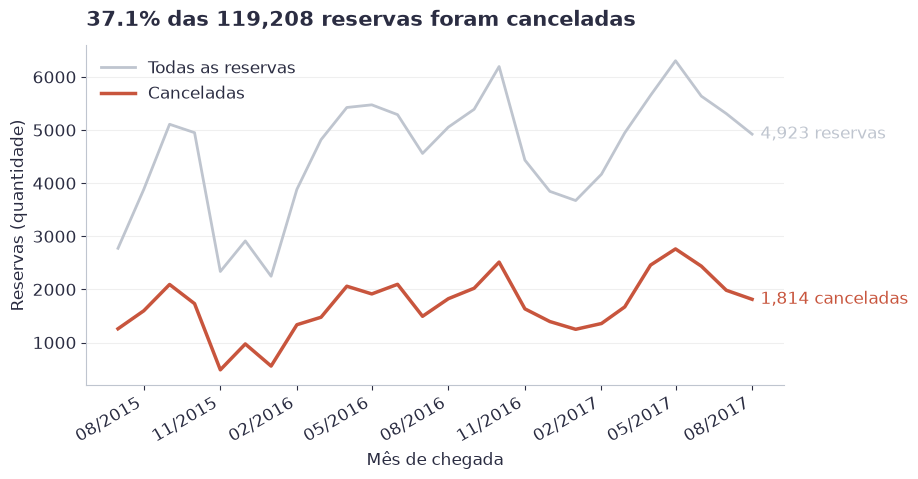

Resposta: são 119,208 reservas de 07/2015 a 08/2017, nos dois hotéis. No total, 37.1% foram canceladas; a linha em destaque mostra quantas canceladas chegaram em cada mês.


In [3]:
mensal = (base.assign(mes=base["data_chegada"].dt.to_period("M"))
          .groupby("mes", observed=True)
          .agg(reservas=("cancelada", "size"), canceladas=("cancelada", "sum"))
          .reset_index())
mensal["data"] = mensal["mes"].dt.to_timestamp()
mensal["taxa_cancelamento_pct"] = mensal["canceladas"] / mensal["reservas"] * 100
salvar_tabela(mensal[["mes", "reservas", "canceladas", "taxa_cancelamento_pct"]].round(1), "02_base")

fig, ax = plt.subplots()
ax.plot(mensal["data"], mensal["reservas"], color=CORES["neutro"], linewidth=2, label="Todas as reservas")
ax.plot(mensal["data"], mensal["canceladas"], color=CORES["destaque"], linewidth=2.5, label="Canceladas")
ax.set_title(f"{total_cancelada:.1f}% das {len(base):,} reservas foram canceladas")
ax.set_xlabel("Mês de chegada")
ax.set_ylabel("Reservas (quantidade)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.legend()
ax.grid(axis="y", alpha=0.2)
for serie, rotulo, cor in [("reservas", "reservas", CORES["neutro"]), ("canceladas", "canceladas", CORES["destaque"])]:
    ax.annotate(f"{mensal.iloc[-1][serie]:,.0f} {rotulo}", (mensal.iloc[-1]["data"], mensal.iloc[-1][serie]),
                xytext=(6, 0), textcoords="offset points", color=cor, va="center")
fig.autofmt_xdate()
salvar_figura(fig, "02_reservas_por_mes")
plt.show()

print(f"Resposta: são {len(base):,} reservas de {base['data_chegada'].min():%m/%Y} a {base['data_chegada'].max():%m/%Y}, nos dois hotéis. No total, {total_cancelada:.1f}% foram canceladas; a linha em destaque mostra quantas canceladas chegaram em cada mês.")

## P1. Quanto cancelamos e quanto isso custa?

Qual é a taxa em cada hotel e qual receita estimada estava associada às reservas canceladas?

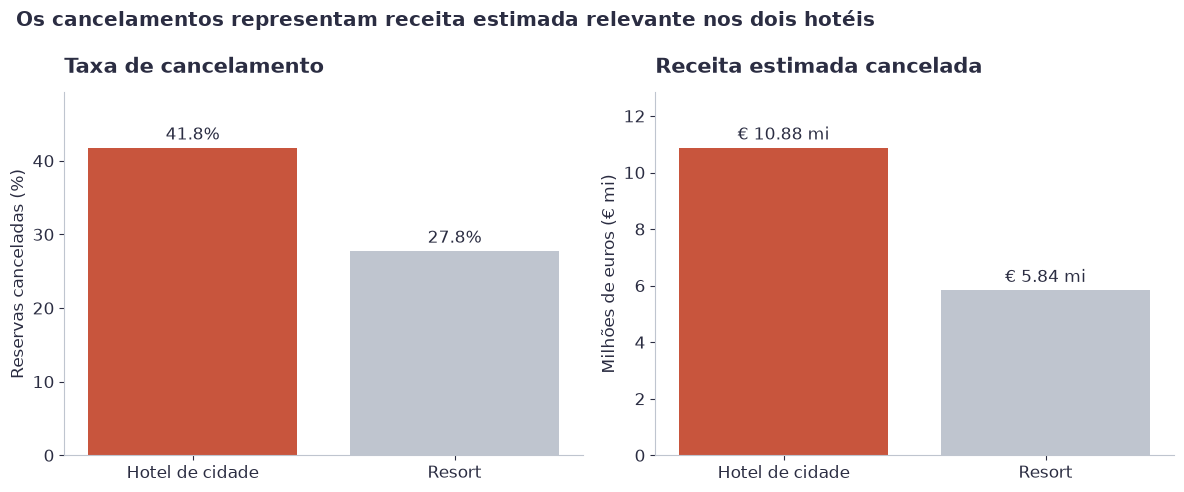

Resposta: Hotel de cidade tem a maior taxa, 41.8%. Somando os dois hotéis, a receita estimada das reservas canceladas é € 16.72 milhões; é uma estimativa, não dinheiro efetivamente recebido.


In [4]:
por_hotel = (base.groupby("hotel", observed=True)
             .agg(reservas=("cancelada", "size"), canceladas=("cancelada", "sum")))
por_hotel["taxa_cancelamento_pct"] = por_hotel["canceladas"] / por_hotel["reservas"] * 100
receita_cancelada = (base.loc[base["cancelada"].eq(1)]
                     .groupby("hotel", observed=True)["receita_estimada"].sum())
por_hotel["receita_estimada_perdida_eur"] = receita_cancelada
salvar_tabela(por_hotel.reset_index().round(2), "02_hotel")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
cores_taxa = [CORES["destaque"] if v == por_hotel["taxa_cancelamento_pct"].max() else CORES["neutro"] for v in por_hotel["taxa_cancelamento_pct"]]
b1 = ax1.bar(por_hotel.index, por_hotel["taxa_cancelamento_pct"], color=cores_taxa)
ax1.bar_label(b1, labels=[f"{v:.1f}%" for v in por_hotel["taxa_cancelamento_pct"]], padding=3)
ax1.set_title("Taxa de cancelamento")
ax1.set_ylabel("Reservas canceladas (%)")
ax1.set_ylim(0, max(por_hotel["taxa_cancelamento_pct"]) * 1.18)
cores_receita = [CORES["destaque"] if v == por_hotel["receita_estimada_perdida_eur"].max() else CORES["neutro"] for v in por_hotel["receita_estimada_perdida_eur"]]
valores_mi = por_hotel["receita_estimada_perdida_eur"] / 1_000_000
b2 = ax2.bar(por_hotel.index, valores_mi, color=cores_receita)
ax2.bar_label(b2, labels=[f"€ {v:.2f} mi" for v in valores_mi], padding=3)
ax2.set_title("Receita estimada cancelada")
ax2.set_ylabel("Milhões de euros (€ mi)")
ax2.set_ylim(0, max(valores_mi) * 1.18)
fig.suptitle("Os cancelamentos representam receita estimada relevante nos dois hotéis", x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
salvar_figura(fig, "02_cancelamento_por_hotel")
plt.show()

maior_taxa = por_hotel["taxa_cancelamento_pct"].idxmax()
print(f"Resposta: {maior_taxa} tem a maior taxa, {por_hotel.loc[maior_taxa, 'taxa_cancelamento_pct']:.1f}%. Somando os dois hotéis, a receita estimada das reservas canceladas é € {por_hotel['receita_estimada_perdida_eur'].sum() / 1_000_000:.2f} milhões; é uma estimativa, não dinheiro efetivamente recebido.")

## P2. Reservar com muita antecedência aumenta o cancelamento?

Comparamos as mesmas seis faixas de dias antes da chegada.

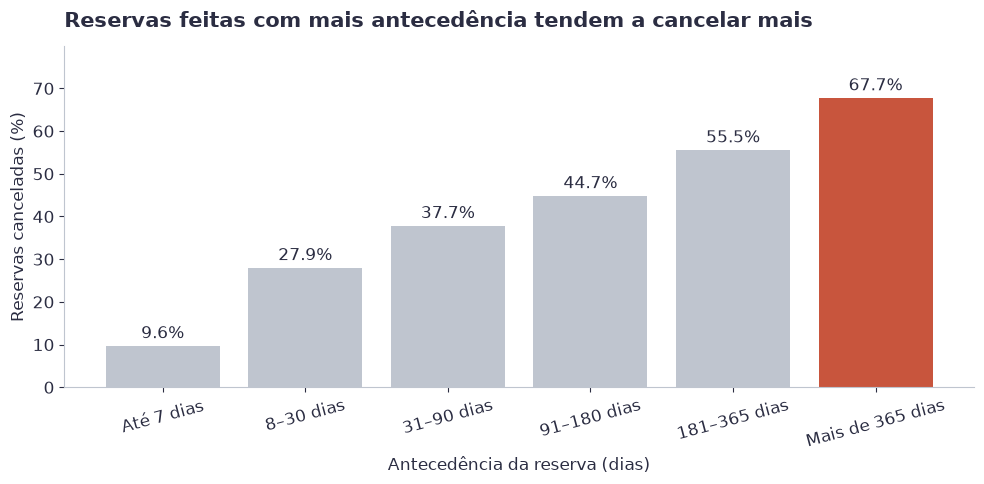

Resposta: 67.7% das reservas feitas com mais de um ano de antecedência foram canceladas, contra 9.6% das feitas até uma semana antes. A associação é forte neste histórico, mas não prova que a antecedência cause o cancelamento.


In [5]:
faixas = ["Até 7 dias", "8–30 dias", "31–90 dias", "91–180 dias", "181–365 dias", "Mais de 365 dias"]
base["faixa_antecedencia"] = pd.cut(base["antecedencia_dias"], bins=[-1, 7, 30, 90, 180, 365, np.inf], labels=faixas, ordered=True)
antecedencia = (base.groupby("faixa_antecedencia", observed=False)
                .agg(reservas=("cancelada", "size"), canceladas=("cancelada", "sum")))
antecedencia["taxa_cancelamento_pct"] = antecedencia["canceladas"] / antecedencia["reservas"] * 100
salvar_tabela(antecedencia.reset_index().round(2), "02_antecedencia")

fig, ax = plt.subplots(figsize=(10, 5))
cores = [CORES["destaque"] if i == len(antecedencia) - 1 else CORES["neutro"] for i in range(len(antecedencia))]
barras = ax.bar(antecedencia.index.astype(str), antecedencia["taxa_cancelamento_pct"], color=cores)
ax.bar_label(barras, labels=[f"{v:.1f}%" for v in antecedencia["taxa_cancelamento_pct"]], padding=3)
ax.set_title("Reservas feitas com mais antecedência tendem a cancelar mais")
ax.set_xlabel("Antecedência da reserva (dias)")
ax.set_ylabel("Reservas canceladas (%)")
ax.set_ylim(0, antecedencia["taxa_cancelamento_pct"].max() * 1.18)
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
salvar_figura(fig, "02_antecedencia")
plt.show()

taxa_curta = antecedencia.loc["Até 7 dias", "taxa_cancelamento_pct"]
taxa_longa = antecedencia.loc["Mais de 365 dias", "taxa_cancelamento_pct"]
print(f"Resposta: {taxa_longa:.1f}% das reservas feitas com mais de um ano de antecedência foram canceladas, contra {taxa_curta:.1f}% das feitas até uma semana antes. A associação é forte neste histórico, mas não prova que a antecedência cause o cancelamento.")

## P3. Em que meses cancelam mais?

A taxa mensal separada por hotel permite comparar meses sem confundir a diferença no volume de reservas.

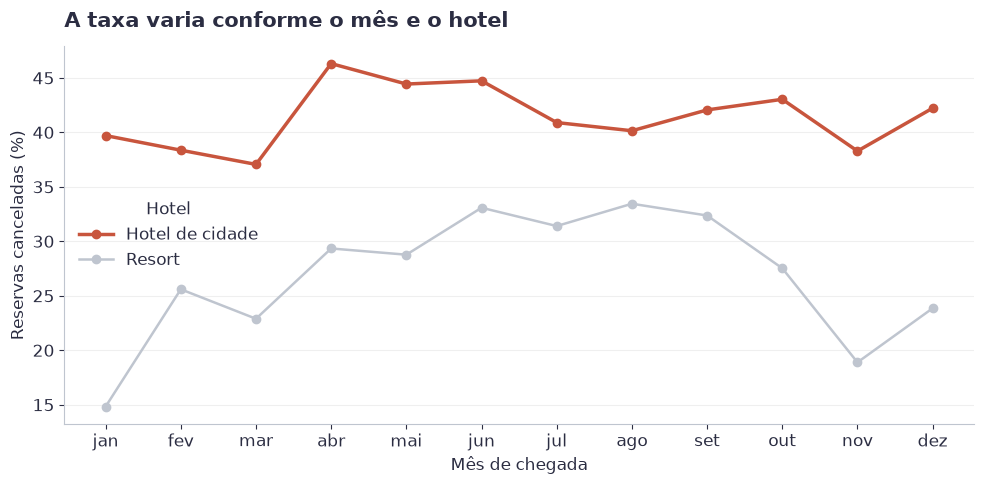

Resposta: o maior valor mensal observado foi 46.3% no Hotel de cidade, em abr. A linha compara as taxas de cada hotel, mês a mês.


In [6]:
sazonal = (base.groupby(["hotel", "mes_chegada"], observed=True)
           .agg(reservas=("cancelada", "size"), canceladas=("cancelada", "sum"))
           .reset_index())
sazonal["taxa_cancelamento_pct"] = sazonal["canceladas"] / sazonal["reservas"] * 100
salvar_tabela(sazonal.round(2), "02_sazonalidade")
meses_pt = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
hotel_maior_taxa = por_hotel["taxa_cancelamento_pct"].idxmax()

fig, ax = plt.subplots(figsize=(10, 5))
for hotel, grupo in sazonal.groupby("hotel", observed=True):
    destaque = hotel == hotel_maior_taxa
    ax.plot(grupo["mes_chegada"], grupo["taxa_cancelamento_pct"], marker="o",
            color=CORES["destaque"] if destaque else CORES["neutro"],
            linewidth=2.5 if destaque else 1.8, label=hotel)
ax.set_title("A taxa varia conforme o mês e o hotel")
ax.set_xlabel("Mês de chegada")
ax.set_ylabel("Reservas canceladas (%)")
ax.set_xticks(range(1, 13), meses_pt)
ax.legend(title="Hotel")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
salvar_figura(fig, "02_sazonalidade")
plt.show()

pico = sazonal.loc[sazonal["taxa_cancelamento_pct"].idxmax()]
print(f"Resposta: o maior valor mensal observado foi {pico['taxa_cancelamento_pct']:.1f}% no {pico['hotel']}, em {meses_pt[int(pico['mes_chegada']) - 1]}. A linha compara as taxas de cada hotel, mês a mês.")

## P4. Por onde vêm as reservas que mais cancelam?

Comparamos a taxa de cancelamento por segmento de mercado, isto é, o tipo de origem comercial da reserva.

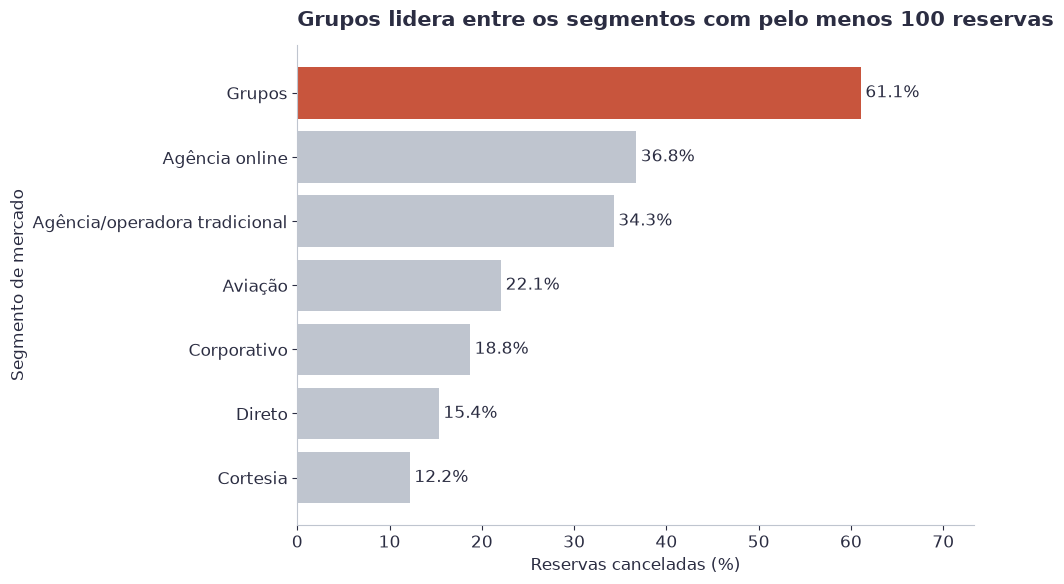

Resposta: entre segmentos com pelo menos 100 reservas, Grupos tem a maior taxa, 61.1% (19,790 reservas). Segmento mostra por onde a reserva chegou; não significa que o canal, sozinho, provoque o cancelamento. A categoria Indefinido teve 100.0%, mas reúne só 2 reservas e não é comparável.


In [7]:
segmentos = (base.groupby("segmento_mercado", observed=True)
             .agg(reservas=("cancelada", "size"), canceladas=("cancelada", "sum")))
segmentos["taxa_cancelamento_pct"] = segmentos["canceladas"] / segmentos["reservas"] * 100
segmentos = segmentos.sort_values("taxa_cancelamento_pct")
salvar_tabela(segmentos.reset_index().round(2), "02_segmento")
segmentos_comparaveis = segmentos.loc[segmentos["reservas"] >= 100]

fig, ax = plt.subplots(figsize=(10, 6))
cores = [CORES["destaque"] if v == segmentos_comparaveis["taxa_cancelamento_pct"].max() else CORES["neutro"] for v in segmentos_comparaveis["taxa_cancelamento_pct"]]
barras = ax.barh(segmentos_comparaveis.index.astype(str), segmentos_comparaveis["taxa_cancelamento_pct"], color=cores)
ax.bar_label(barras, labels=[f"{v:.1f}%" for v in segmentos_comparaveis["taxa_cancelamento_pct"]], padding=3)
ax.set_title("Grupos lidera entre os segmentos com pelo menos 100 reservas")
ax.set_xlabel("Reservas canceladas (%)")
ax.set_ylabel("Segmento de mercado")
ax.set_xlim(0, segmentos_comparaveis["taxa_cancelamento_pct"].max() * 1.2)
fig.tight_layout()
salvar_figura(fig, "02_segmento")
plt.show()

mais_segmento = segmentos_comparaveis.iloc[-1]
indefinido = segmentos.loc["Indefinido"] if "Indefinido" in segmentos.index else None
nota_indefinido = f" A categoria Indefinido teve {indefinido['taxa_cancelamento_pct']:.1f}%, mas reúne só {int(indefinido['reservas'])} reservas e não é comparável." if indefinido is not None else ""
print(f"Resposta: entre segmentos com pelo menos 100 reservas, {mais_segmento.name} tem a maior taxa, {mais_segmento['taxa_cancelamento_pct']:.1f}% ({int(mais_segmento['reservas']):,} reservas). Segmento mostra por onde a reserva chegou; não significa que o canal, sozinho, provoque o cancelamento.{nota_indefinido}")

## P5. O paradoxo do depósito: quem paga adiantado cancela menos?

O tipo de depósito é a regra registrada para o pagamento antecipado. Um resultado contraintuitivo deve ser tratado como pista para investigação, não como explicação definitiva.

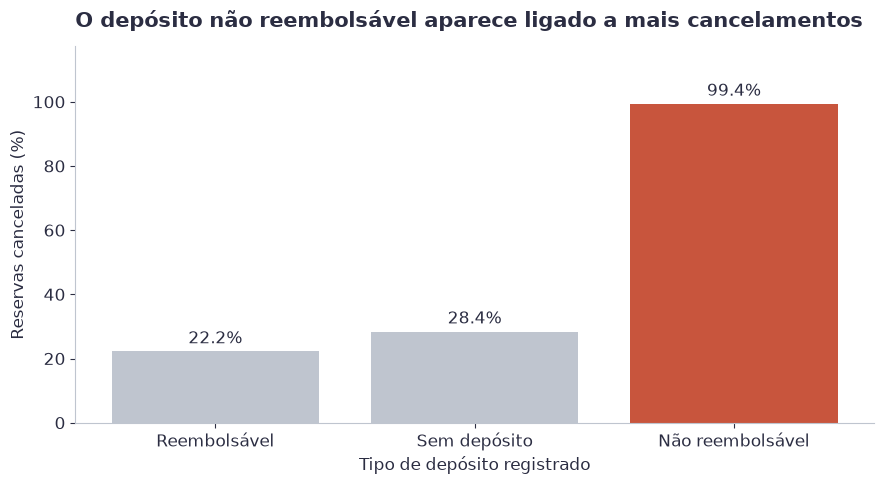

Resposta: 99.4% das reservas marcadas como não reembolsáveis foram canceladas, um resultado contraintuitivo. Reservas de grupos ou operadoras feitas em bloco e liberadas depois, ou erro de registro, são hipóteses; é um achado para o hotel investigar, não uma conclusão sobre o motivo.


In [8]:
depositos = (base.groupby("tipo_deposito", observed=True)
             .agg(reservas=("cancelada", "size"), canceladas=("cancelada", "sum")))
depositos["taxa_cancelamento_pct"] = depositos["canceladas"] / depositos["reservas"] * 100
depositos = depositos.sort_values("taxa_cancelamento_pct")
salvar_tabela(depositos.reset_index().round(2), "02_deposito")

fig, ax = plt.subplots(figsize=(9, 5))
cores = [CORES["destaque"] if str(v) == "Não reembolsável" else CORES["neutro"] for v in depositos.index]
barras = ax.bar(depositos.index.astype(str), depositos["taxa_cancelamento_pct"], color=cores)
ax.bar_label(barras, labels=[f"{v:.1f}%" for v in depositos["taxa_cancelamento_pct"]], padding=3)
ax.set_title("O depósito não reembolsável aparece ligado a mais cancelamentos")
ax.set_xlabel("Tipo de depósito registrado")
ax.set_ylabel("Reservas canceladas (%)")
ax.set_ylim(0, depositos["taxa_cancelamento_pct"].max() * 1.18)
fig.tight_layout()
salvar_figura(fig, "02_deposito")
plt.show()

nao_reemb = depositos.loc["Não reembolsável", "taxa_cancelamento_pct"]
print(f"Resposta: {nao_reemb:.1f}% das reservas marcadas como não reembolsáveis foram canceladas, um resultado contraintuitivo. Reservas de grupos ou operadoras feitas em bloco e liberadas depois, ou erro de registro, são hipóteses; é um achado para o hotel investigar, não uma conclusão sobre o motivo.")

## P6. Hóspedes fiéis e que fazem pedidos cancelam menos?

Comparamos a taxa por número de pedidos especiais e por histórico de hóspede recorrente.

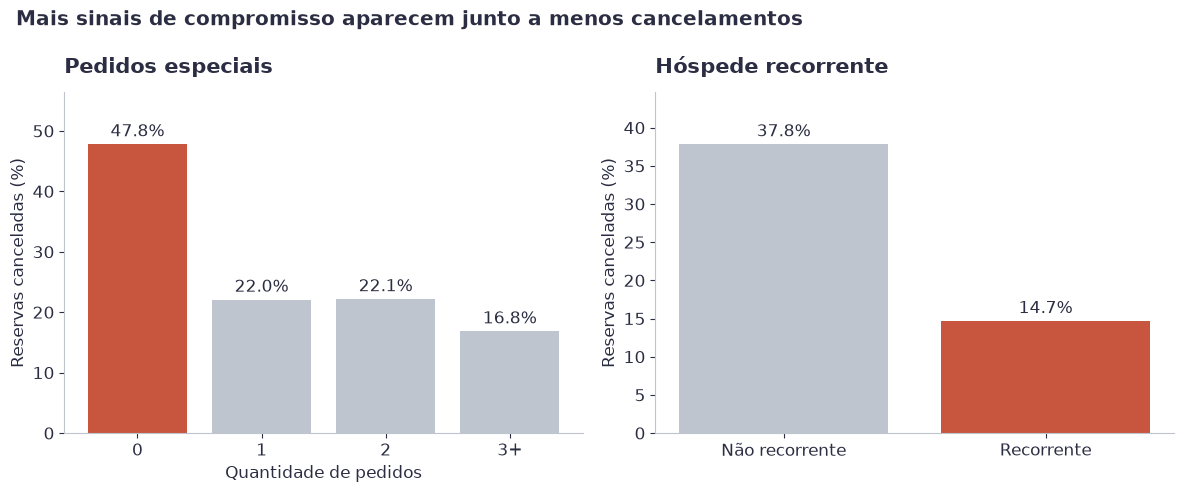

Resposta: sem pedidos especiais, 47.8% cancelam; com 3 ou mais, 16.8%. Entre hóspedes recorrentes, a taxa é 14.7%, contra 37.8% entre os demais.


In [9]:
base["faixa_pedidos"] = base["pedidos_especiais"].map(lambda n: "3+" if n >= 3 else str(int(n)))
ordem_pedidos = ["0", "1", "2", "3+"]
pedidos = (base.groupby("faixa_pedidos", observed=True)
           .agg(reservas=("cancelada", "size"), canceladas=("cancelada", "sum"))
           .reindex(ordem_pedidos))
pedidos["taxa_cancelamento_pct"] = pedidos["canceladas"] / pedidos["reservas"] * 100
fidelidade_base = base.assign(historico_recorrencia=base["hospede_recorrente"].map({0: "Não recorrente", 1: "Recorrente"}))
fidelidade = (fidelidade_base.groupby("historico_recorrencia", observed=True)
              .agg(reservas=("cancelada", "size"), canceladas=("cancelada", "sum"))
              .reindex(["Não recorrente", "Recorrente"]))
fidelidade["taxa_cancelamento_pct"] = fidelidade["canceladas"] / fidelidade["reservas"] * 100
salvar_tabela(pedidos.reset_index().round(2), "02_compromisso_pedidos")
salvar_tabela(fidelidade.reset_index().round(2), "02_compromisso_recorrencia")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
cores_pedidos = [CORES["destaque"] if i == 0 else CORES["neutro"] for i in range(len(pedidos))]
b1 = ax1.bar(pedidos.index, pedidos["taxa_cancelamento_pct"], color=cores_pedidos)
ax1.bar_label(b1, labels=[f"{v:.1f}%" for v in pedidos["taxa_cancelamento_pct"]], padding=3)
ax1.set_title("Pedidos especiais")
ax1.set_xlabel("Quantidade de pedidos")
ax1.set_ylabel("Reservas canceladas (%)")
ax1.set_ylim(0, pedidos["taxa_cancelamento_pct"].max() * 1.18)
cores_fiel = [CORES["destaque"] if nome == fidelidade["taxa_cancelamento_pct"].idxmin() else CORES["neutro"] for nome in fidelidade.index]
b2 = ax2.bar(fidelidade.index, fidelidade["taxa_cancelamento_pct"], color=cores_fiel)
ax2.bar_label(b2, labels=[f"{v:.1f}%" for v in fidelidade["taxa_cancelamento_pct"]], padding=3)
ax2.set_title("Hóspede recorrente")
ax2.set_ylabel("Reservas canceladas (%)")
ax2.set_ylim(0, fidelidade["taxa_cancelamento_pct"].max() * 1.18)
fig.suptitle("Mais sinais de compromisso aparecem junto a menos cancelamentos", x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
salvar_figura(fig, "02_compromisso")
plt.show()

print(f"Resposta: sem pedidos especiais, {pedidos.loc['0', 'taxa_cancelamento_pct']:.1f}% cancelam; com 3 ou mais, {pedidos.loc['3+', 'taxa_cancelamento_pct']:.1f}%. Entre hóspedes recorrentes, a taxa é {fidelidade.loc['Recorrente', 'taxa_cancelamento_pct']:.1f}%, contra {fidelidade.loc['Não recorrente', 'taxa_cancelamento_pct']:.1f}% entre os demais.")

## P7. Quem já cancelou antes cancela de novo?

Agrupamos os hóspedes sem cancelamentos anteriores e os que têm um ou mais.

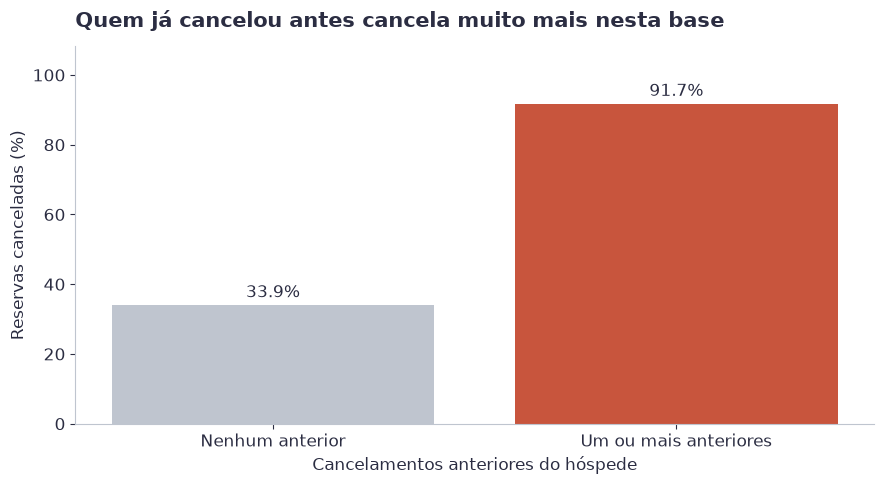

Resposta: quem já cancelou antes tem taxa de 91.7%; quem não tinha cancelamentos anteriores, 33.9%. O histórico, sozinho, não explica por que a reserva atual foi cancelada.


In [10]:
base["historico_cancelamento"] = np.where(base["cancelamentos_anteriores"].eq(0), "Nenhum anterior", "Um ou mais anteriores")
historico = (base.groupby("historico_cancelamento", observed=True)
             .agg(reservas=("cancelada", "size"), canceladas=("cancelada", "sum"))
             .reindex(["Nenhum anterior", "Um ou mais anteriores"]))
historico["taxa_cancelamento_pct"] = historico["canceladas"] / historico["reservas"] * 100
salvar_tabela(historico.reset_index().round(2), "02_historico")

fig, ax = plt.subplots(figsize=(9, 5))
cores = [CORES["destaque"] if nome == "Um ou mais anteriores" else CORES["neutro"] for nome in historico.index]
barras = ax.bar(historico.index, historico["taxa_cancelamento_pct"], color=cores)
ax.bar_label(barras, labels=[f"{v:.1f}%" for v in historico["taxa_cancelamento_pct"]], padding=3)
ax.set_title("Quem já cancelou antes cancela muito mais nesta base")
ax.set_xlabel("Cancelamentos anteriores do hóspede")
ax.set_ylabel("Reservas canceladas (%)")
ax.set_ylim(0, historico["taxa_cancelamento_pct"].max() * 1.18)
fig.tight_layout()
salvar_figura(fig, "02_historico")
plt.show()

print(f"Resposta: quem já cancelou antes tem taxa de {historico.loc['Um ou mais anteriores', 'taxa_cancelamento_pct']:.1f}%; quem não tinha cancelamentos anteriores, {historico.loc['Nenhum anterior', 'taxa_cancelamento_pct']:.1f}%. O histórico, sozinho, não explica por que a reserva atual foi cancelada.")

## Uma pista para investigar: o país informado

O ETL mantém o país como código; `PRT` corresponde a Portugal. Como o país pode ser informado só perto do check-in, essa diferença pode refletir registro tardio, e não o país causando cancelamento.

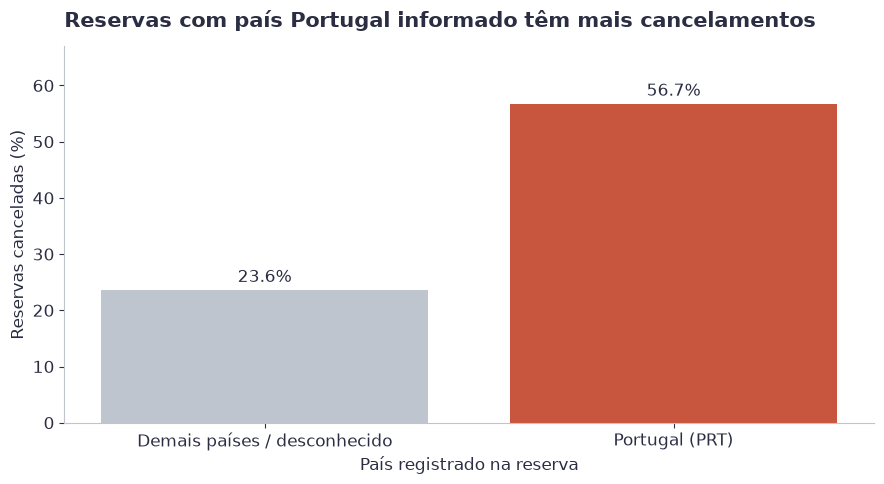

Resposta: 56.7% das reservas com país Portugal (PRT) informado cancelaram, contra 23.6% das demais. A diferença é uma pista, não prova: o país pode ter sido preenchido tarde, por exemplo no check-in, por isso não será tratado como causa nem como fator para o modelo.


In [11]:
base["grupo_pais"] = np.where(base["pais"].astype(str).eq("PRT"), "Portugal (PRT)", "Demais países / desconhecido")
pais_eda = (base.groupby("grupo_pais", observed=True)
            .agg(reservas=("cancelada", "size"), canceladas=("cancelada", "sum")))
pais_eda["taxa_cancelamento_pct"] = pais_eda["canceladas"] / pais_eda["reservas"] * 100
salvar_tabela(pais_eda.reset_index().round(2), "02_pais")

fig, ax = plt.subplots(figsize=(9, 5))
cores = [CORES["destaque"] if nome == "Portugal (PRT)" else CORES["neutro"] for nome in pais_eda.index]
barras = ax.bar(pais_eda.index, pais_eda["taxa_cancelamento_pct"], color=cores)
ax.bar_label(barras, labels=[f"{v:.1f}%" for v in pais_eda["taxa_cancelamento_pct"]], padding=3)
ax.set_title("Reservas com país Portugal informado têm mais cancelamentos")
ax.set_xlabel("País registrado na reserva")
ax.set_ylabel("Reservas canceladas (%)")
ax.set_ylim(0, pais_eda["taxa_cancelamento_pct"].max() * 1.18)
fig.tight_layout()
salvar_figura(fig, "02_pais")
plt.show()

taxa_prt = pais_eda.loc["Portugal (PRT)", "taxa_cancelamento_pct"]
taxa_outros = pais_eda.loc["Demais países / desconhecido", "taxa_cancelamento_pct"]
print(f"Resposta: {taxa_prt:.1f}% das reservas com país Portugal (PRT) informado cancelaram, contra {taxa_outros:.1f}% das demais. A diferença é uma pista, não prova: o país pode ter sido preenchido tarde, por exemplo no check-in, por isso não será tratado como causa nem como fator para o modelo.")

## As 5 descobertas principais

Os números abaixo são calculados diretamente da base completa e aparecem também nas tabelas desta análise.

In [12]:
taxa_historico = historico.loc["Um ou mais anteriores", "taxa_cancelamento_pct"]
taxa_sem_historico = historico.loc["Nenhum anterior", "taxa_cancelamento_pct"]
descobertas = [
    {"descoberta": "Reservas feitas com mais de um ano de antecedência cancelam mais que as feitas na semana da chegada.",
     "número": f"{taxa_longa:.1f}% contra {taxa_curta:.1f}%",
     "figura": "02_antecedencia.png"},
    {"descoberta": "Quem já cancelou antes tem uma taxa maior de novo cancelamento.",
     "número": f"{taxa_historico:.1f}% contra {taxa_sem_historico:.1f}% sem cancelamentos anteriores",
     "figura": "02_historico.png"},
    {"descoberta": "Grupos têm a maior taxa entre segmentos com pelo menos 100 reservas.",
     "número": f"{mais_segmento['taxa_cancelamento_pct']:.1f}% ({int(mais_segmento['reservas']):,} reservas)",
     "figura": "02_segmento.png"},
    {"descoberta": "O depósito não reembolsável aparece associado a uma taxa de cancelamento muito alta e precisa ser investigado.",
     "número": f"{nao_reemb:.1f}% canceladas",
     "figura": "02_deposito.png"},
    {"descoberta": "Pedidos especiais aparecem associados a menos cancelamentos.",
     "número": f"{pedidos.loc['0', 'taxa_cancelamento_pct']:.1f}% sem pedidos contra {pedidos.loc['3+', 'taxa_cancelamento_pct']:.1f}% com 3 ou mais",
     "figura": "02_compromisso.png"},
]
salvar_tabela(pd.DataFrame(descobertas), "02_descobertas")
for i, item in enumerate(descobertas, 1):
    print(f"{i}. {item['descoberta']} {item['número']}.")

fatores = [
    f"Antecedência: {taxa_longa:.1f}% com mais de 365 dias contra {taxa_curta:.1f}% até 7 dias.",
    f"Tipo de depósito: {nao_reemb:.1f}% nas reservas não reembolsáveis; validar o registro com o hotel.",
    f"Segmento de mercado: maior taxa em {mais_segmento.name} ({mais_segmento['taxa_cancelamento_pct']:.1f}%).",
    f"Pedidos especiais: {pedidos.loc['0', 'taxa_cancelamento_pct']:.1f}% sem pedidos contra {pedidos.loc['3+', 'taxa_cancelamento_pct']:.1f}% com 3 ou mais.",
    f"Histórico anterior: {taxa_historico:.1f}% com cancelamento anterior contra {taxa_sem_historico:.1f}% sem histórico.",
]
print("\nPistas para a previsão (o notebook 03 vai confirmar ou não se ajudam a prever):")
for fator in fatores:
    print(f"- {fator}")
print("O país não entra como pista do modelo: há suspeita de preenchimento tardio, então a diferença por país não deve ser interpretada como causa.")

1. Reservas feitas com mais de um ano de antecedência cancelam mais que as feitas na semana da chegada. 67.7% contra 9.6%.
2. Quem já cancelou antes tem uma taxa maior de novo cancelamento. 91.7% contra 33.9% sem cancelamentos anteriores.
3. Grupos têm a maior taxa entre segmentos com pelo menos 100 reservas. 61.1% (19,790 reservas).
4. O depósito não reembolsável aparece associado a uma taxa de cancelamento muito alta e precisa ser investigado. 99.4% canceladas.
5. Pedidos especiais aparecem associados a menos cancelamentos. 47.8% sem pedidos contra 16.8% com 3 ou mais.

Pistas para a previsão (o notebook 03 vai confirmar ou não se ajudam a prever):
- Antecedência: 67.7% com mais de 365 dias contra 9.6% até 7 dias.
- Tipo de depósito: 99.4% nas reservas não reembolsáveis; validar o registro com o hotel.
- Segmento de mercado: maior taxa em Grupos (61.1%).
- Pedidos especiais: 47.8% sem pedidos contra 16.8% com 3 ou mais.
- Histórico anterior: 91.7% com cancelamento anterior contra 33.